# Libraries

## Classical CNN model

In [1]:
# Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2026-08-05 14:02:58.739762: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785938578.926989      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785938578.984798      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1785938579.412884      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785938579.412924      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1785938579.412927      57 computation_placer.cc:177] computation placer alr

In [6]:
import os
import random
import numpy as np
import torch
import tensorflow as tf

seed = 42

os.environ["PYTHONHASHSEED"] = str(seed)

random.seed(seed)
np.random.seed(seed)

torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

tf.random.set_seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [7]:
from torch.utils.data import DataLoader

In [21]:
g = torch.Generator()
g.manual_seed(seed)

trainloader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=g)
testloader  = DataLoader(test_ds, batch_size=32, shuffle=False)

In [9]:
DATASET_PATH = "/kaggle/input/datasets/artyomkolas/3-kinds-of-pneumonia/Curated X-Ray Dataset"

Creating train, test and validation data

In [10]:
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(128,128),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

val_data = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(128,128),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42
)

Found 7367 images belonging to 4 classes.
Found 1841 images belonging to 4 classes.


Building a model

In [11]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

Dataset

In [12]:
DATASET_PATH = Path("/kaggle/input/datasets/artyomkolas/3-kinds-of-pneumonia/Curated X-Ray Dataset")

In [13]:
#labels = ['COVID-19', 'Normal','Pneumonia-Bacterial','Pneumonia-viral']
COVID_19 = list((DATASET_PATH/"COVID-19").glob("*"))
Normal = list((DATASET_PATH/"Normal").glob("*"))
Pneumonia_Bacterial = list((DATASET_PATH/"Pneumonia-Bacterial").glob("*"))
Pneumonia_Viral = list((DATASET_PATH/"Pneumonia-Viral").glob("*"))
random.seed(42)
print("COVID-19:", len(COVID_19))
print("Normal:", len(Normal))
print("Pneumonia-Bacterial:", len(Pneumonia_Bacterial))
print("Pneumonia-Viral:", len(Pneumonia_Viral))


COVID-19: 1281
Normal: 3270
Pneumonia-Bacterial: 3001
Pneumonia-Viral: 1656


In [14]:
COVID_19=random.sample(COVID_19,800)
Normal=random.sample(Normal,3270)
Pneumonia_Bacterial=random.sample(Pneumonia_Bacterial,1600)
Pneumonia_Viral=random.sample(Pneumonia_Viral,900)

In [15]:
print("COVID-19:", len(COVID_19))
print("Normal:", len(Normal))
print("Pneumonia-Bacterial:", len(Pneumonia_Bacterial))
print("Pneumonia-Viral:", len(Pneumonia_Viral))

COVID-19: 800
Normal: 3270
Pneumonia-Bacterial: 1600
Pneumonia-Viral: 900


In [16]:
files = []
labels = []

for f in Normal:
    files.append(str(f))
    labels.append(0)

for f in Pneumonia_Bacterial + Pneumonia_Viral + COVID_19:
    files.append(str(f))
    labels.append(1)

print("Total images:", len(files))

Total images: 6570


In [22]:
from sklearn.model_selection import train_test_split

train_files, test_files, train_labels, test_labels = train_test_split(
    files, labels, test_size=0.15, random_state=42, stratify=labels
)

train_files, val_files, train_labels, val_labels = train_test_split(
    train_files, train_labels, test_size=0.15, random_state=42, stratify=train_labels
)

print(len(train_files), len(val_files), len(test_files))

4746 838 986


In [23]:
IMG_SIZE = (128,128)

def preprocess(path, label):

    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)

    img = tf.image.resize(img, IMG_SIZE)

    img = tf.cast(img, tf.float32)/255.0

    return img, label

In [24]:
def create_dataset(files, labels):

    ds = tf.data.Dataset.from_tensor_slices((files, labels))

    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(32)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

In [20]:
train_ds = create_dataset(train_files, train_labels)
val_ds = create_dataset(val_files, val_labels)
test_ds = create_dataset(test_files, test_labels)

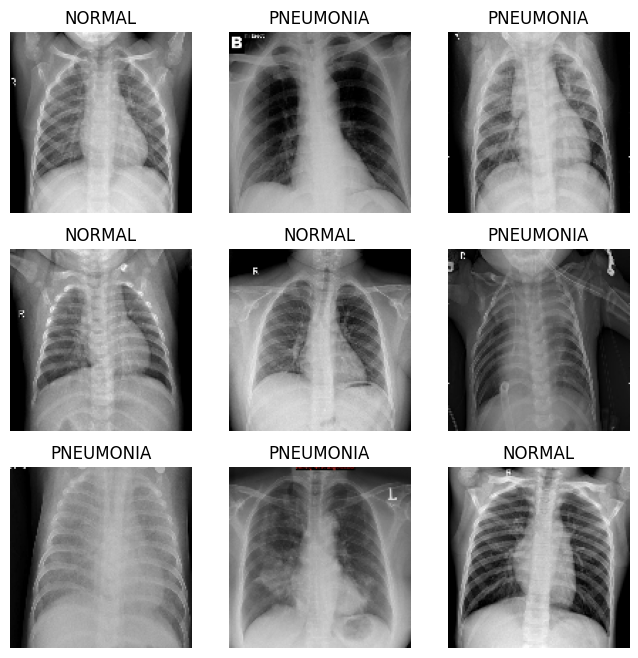

In [25]:
plt.figure(figsize=(8,8))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i])

        plt.title("PNEUMONIA" if labels[i]==1 else "NORMAL")

        plt.axis("off")

plt.show()

In [26]:
print(len(train_files))
print(len(test_files))
print(len(val_files))

4746
986
838


In [27]:
## Accuracy 93%
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128,128,3)),

    tf.keras.layers.Conv2D(64,(3,3),activation="relu",padding='same'),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),

    tf.keras.layers.Resizing(6,6),
    tf.keras.layers.AveragePooling2D(pool_size=(1,1)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(1,activation="sigmoid")
])

In [28]:
model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=["accuracy"]
)

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 6, 6, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 149,377 (583.50 KB)

 Trainable params: 149,377 (583.50 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=20
)
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)

Epoch 1/20


I0000 00:00:1785938788.485739     128 service.cc:152] XLA service 0x7f5b80005430 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785938788.485791     128 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1785938788.888418     128 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/149 ━━━━━━━━━━━━━━━━━━━━ 9:13 4s/step - accuracy: 0.5938 - loss: 0.6924

I0000 00:00:1785938791.130494     128 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


149/149 ━━━━━━━━━━━━━━━━━━━━ 36s 218ms/step - accuracy: 0.6270 - loss: 0.6355 - val_accuracy: 0.7852 - val_loss: 0.4457
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 130ms/step - accuracy: 0.7865 - loss: 0.4513 - val_accuracy: 0.8401 - val_loss: 0.3531
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 126ms/step - accuracy: 0.8344 - loss: 0.3775 - val_accuracy: 0.8449 - val_loss: 0.3421
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 125ms/step - accuracy: 0.8473 - loss: 0.3538 - val_accuracy: 0.8556 - val_loss: 0.3235
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - accuracy: 0.8635 - loss: 0.3357 - val_accuracy: 0.8890 - val_loss: 0.2833
Epoch 6/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 21s 140ms/step - accuracy: 0.8806 - loss: 0.3028 - val_accuracy: 0.8962 - val_loss: 0.2595
Epoch 7/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 125ms/step - accuracy: 0.8866 - loss: 0.2781 - val_accuracy: 0.9045 - val_loss: 0.2442
Epoch 8/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - accuracy: 0.8878 - loss: 0.2683 - val

Confusion Matrix for CNN

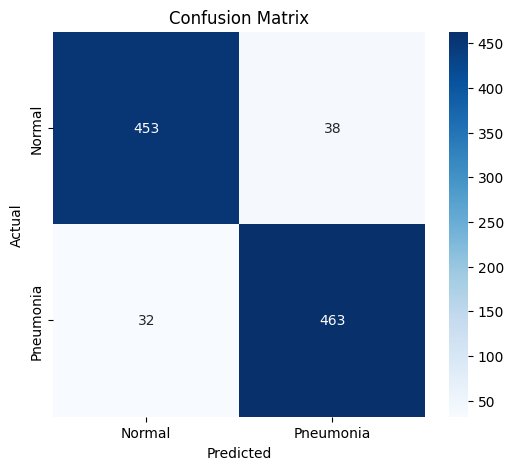

              precision    recall  f1-score   support

      Normal       0.93      0.92      0.93       491
   Pneumonia       0.92      0.94      0.93       495

    accuracy                           0.93       986
   macro avg       0.93      0.93      0.93       986
weighted avg       0.93      0.93      0.93       986



In [30]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:

    preds = model.predict(images, verbose=0)

    preds = (preds > 0.5).astype(int).flatten()

    y_pred.extend(preds)
    y_true.extend(labels.numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal','Pneumonia'],
    yticklabels=['Normal','Pneumonia']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=['Normal','Pneumonia']
))

Grad-Cam images 

In [35]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.outputs[0]
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap /= (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

Using layer: conv2d_2


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_18']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


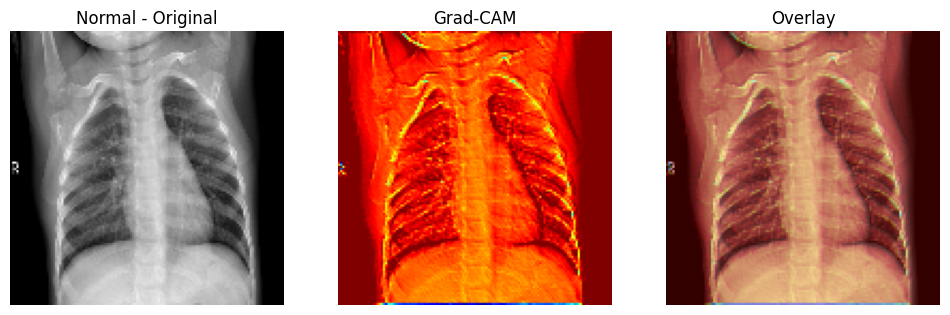

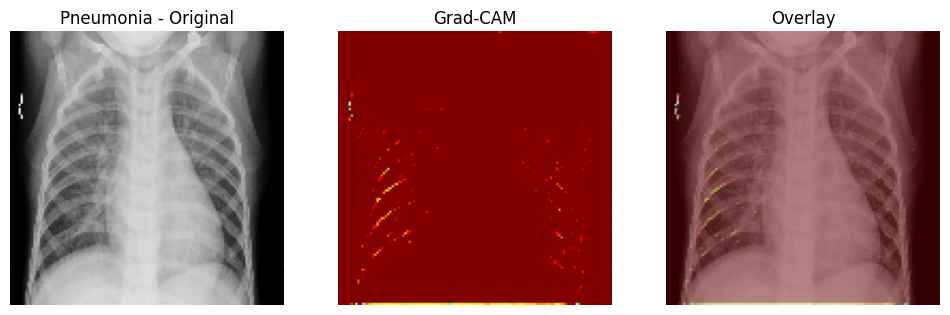

In [37]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Automatically find the Conv2D layer
last_conv_layer_name = model.layers[0].name
print("Using layer:", last_conv_layer_name)

def show_gradcam(img, title):

    heatmap = make_gradcam_heatmap(
        np.expand_dims(img, axis=0),
        model,
        last_conv_layer_name
    )

    heatmap = cv2.resize(heatmap, (128,128))

    heatmap_uint8 = np.uint8(255 * heatmap)

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    original = np.uint8(img * 255)

    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(original)
    plt.title(f"{title} - Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(heatmap_color)
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(overlay)
    plt.title("Overlay")
    plt.axis("off")

    plt.show()

# Normal image
show_gradcam(normal_img, "Normal")

# Pneumonia image
show_gradcam(pneumonia_img, "Pneumonia")

## QCNN WITHOUT IMPROVEMENT (ACCURACY 94.32%)

In [25]:

!pip install pennylane pennylane-lightning -q

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import tensorflow as tf

############################################
# 🔹 GLOBAL SEEDS (Reproducibility)
############################################
seed = 42
os.environ["PYTHONHASHSEED"] = str(seed)
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
tf.random.set_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

############################################
# 🔹 Convert TensorFlow Dataset → NumPy
############################################
def tf_to_numpy(dataset):
    images, labels = [], []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    return np.concatenate(images), np.concatenate(labels)

X_train, y_train = tf_to_numpy(train_ds)
X_test, y_test   = tf_to_numpy(test_ds)

############################################
# 🔹 Convert NumPy → PyTorch
############################################
X_train = torch.tensor(X_train).permute(0,3,1,2).float() / 255.0
X_test  = torch.tensor(X_test).permute(0,3,1,2).float() / 255.0

y_train = torch.tensor(y_train).float()
y_test  = torch.tensor(y_test).float()
# Binary labels
y_train = (y_train > 0).float()
y_test  = (y_test > 0).float()

############################################
# 🔹 DataLoader (Deterministic)
############################################
train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test, y_test)

g = torch.Generator()
g.manual_seed(seed)

trainloader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=g)
testloader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

############################################
# 🔹 Quantum Circuit
############################################
n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

weight_shapes = {"weights": (5, n_qubits, 3)}
quantum_layer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

############################################
# 🔹 Hybrid Quantum CNN
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super(HybridQCNN, self).__init__()

        # Classical CNN
        self.conv = nn.Sequential(
            nn.Conv2d(3,16,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((6,6)),
            nn.BatchNorm2d(16)
        )

        self.flatten = nn.Flatten()

        # Fully connected before quantum layer
        self.fc1 = nn.Sequential(
            nn.Linear(16*6*6,128),  
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_qubits) 
        )

        # Quantum layer
        self.quantum = quantum_layer

        # Output layer
        self.fc2 = nn.Linear(n_qubits,1)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = torch.tanh(x) * np.pi  # scale for quantum angles
        x = self.quantum(x)
        x = self.fc2(x)
        return x

model = HybridQCNN()

############################################
# 🔹 Training Setup
############################################
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()])
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.0003)

############################################
# 🔹 Training Loop with gradient clipping
############################################
for epoch in range(20):
    running_loss = 0.0
    for images, labels in trainloader:
        labels = labels.unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")

############################################
# 🔹 Testing
############################################
correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        labels = labels.unsqueeze(1)
        outputs = model(images)
        probs = torch.sigmoid(outputs)
        predicted = (probs > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

############################################
# 🔹 Verification: first few weights and batch labels
############################################
print("First few model parameters:")
for name, param in model.named_parameters():
    print(name, param.view(-1)[:5])
    break

print("First batch labels:")
for images, labels in trainloader:
    print(labels[:10])
    break

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 79.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 76.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 93.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 116.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 12.5 MB/s eta 0:00:00
Epoch 1, Loss: 0.6237
Epoch 2, Loss: 0.5419
Epoch 3, Loss: 0.4818
Epoch 4, Loss: 0.4310
Epoch 5, Loss: 0.3850
Epoch 6, Loss: 0.3476
Epoch 7, Loss: 0.3206
Epoch 8, Loss: 0.2916
Epoch 9, Loss: 0.2692
Epoch 10, Loss: 0.2483
Epoch 11, Loss: 0.2328
Epoch 12, Loss: 0.2178
Epoch 13, Loss: 0.2085
Epoch 14, Loss: 0.2048
Epoch 15, Loss: 0.1847
Epoch 16, Loss: 0.1803
Epoch 17, Loss: 0.1710
Epoch 18, Loss: 0.1640
Epoch 19, Loss: 0

## QCNN WITH IMPROVEMENT (2 different quantum layers) (ACCURACY 95.33%)

In [26]:

!pip install pennylane pennylane-lightning -q

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import tensorflow as tf

############################################
# 🔹 GLOBAL SEEDS
############################################
seed = 42
os.environ["PYTHONHASHSEED"] = str(seed)
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
tf.random.set_seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

############################################
# 🔹 Convert TensorFlow Dataset → NumPy
############################################
def tf_to_numpy(dataset):
    images, labels = [], []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    return np.concatenate(images), np.concatenate(labels)

X_train, y_train = tf_to_numpy(train_ds)
X_test, y_test   = tf_to_numpy(test_ds)

############################################
# 🔹 Convert NumPy → PyTorch
############################################
X_train = torch.tensor(X_train).permute(0,3,1,2).float() / 255.0
X_test  = torch.tensor(X_test).permute(0,3,1,2).float() / 255.0

y_train = torch.tensor(y_train).float()
y_test  = torch.tensor(y_test).float()

# Binary labels (unchanged)
y_train = (y_train > 0).float()
y_test  = (y_test > 0).float()

############################################
# 🔹 DataLoader
############################################
train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test, y_test)

g = torch.Generator()
g.manual_seed(seed)

trainloader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=g)
testloader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

n_qubits = 6
dev = qml.device("default.qubit", wires=n_qubits)

# 🔹 Quantum Circuit 1
@qml.qnode(dev, interface="torch")
def quantum_circuit_1(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]


# 🔹 Quantum Circuit 2 (different ansatz)
@qml.qnode(dev, interface="torch")
def quantum_circuit_2(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    
    # Different structure: add extra rotations + different entanglement
    for i in range(n_qubits):
        qml.RY(weights[0][i][0], wires=i)
        qml.RZ(weights[0][i][1], wires=i)
    
    for i in range(n_qubits - 1):
        qml.CNOT(wires=[i, i+1])
    
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]


weight_shapes = {"weights": (5, n_qubits, 3)}

quantum_layer1 = qml.qnn.TorchLayer(quantum_circuit_1, weight_shapes)
quantum_layer2 = qml.qnn.TorchLayer(quantum_circuit_2, weight_shapes)

############################################
# 🔹 Hybrid Multi-Branch QCNN
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super(HybridQCNN, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3,16,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((6,6)),
            nn.BatchNorm2d(64)
        )

        self.flatten = nn.Flatten()

        self.fc1 = nn.Sequential(
            nn.Linear(64*6*6,128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_qubits)
        )

        self.quantum1 = quantum_layer1
        self.quantum2 = quantum_layer2

        self.fc2 = nn.Linear(2 * n_qubits, 1)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.fc1(x)

        x = torch.tanh(x) * np.pi

        x1 = self.quantum1(x)
        x2 = self.quantum2(x)

        x = torch.cat([x1, x2], dim=1)

        x = self.fc2(x)
        return x

############################################
# 🔹 Model
############################################
model = HybridQCNN()

############################################
# 🔹 Training Setup
############################################
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()])
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.0003)

############################################
# 🔹 Training Loop
############################################
for epoch in range(20):
    running_loss = 0.0

    for images, labels in trainloader:
        labels = labels.unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")

############################################
# 🔹 Testing
############################################
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        labels = labels.unsqueeze(1)

        outputs = model(images)
        probs = torch.sigmoid(outputs)
        predicted = (probs > 0.5).float()

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Epoch 1, Loss: 0.6579
Epoch 2, Loss: 0.5075
Epoch 3, Loss: 0.4160
Epoch 4, Loss: 0.3445
Epoch 5, Loss: 0.2861
Epoch 6, Loss: 0.2495
Epoch 7, Loss: 0.2158
Epoch 8, Loss: 0.1918
Epoch 9, Loss: 0.1768
Epoch 10, Loss: 0.1633
Epoch 11, Loss: 0.1472
Epoch 12, Loss: 0.1436
Epoch 13, Loss: 0.1357
Epoch 14, Loss: 0.1344
Epoch 15, Loss: 0.1238
Epoch 16, Loss: 0.1116
Epoch 17, Loss: 0.1085
Epoch 18, Loss: 0.1057
Epoch 19, Loss: 0.1067
Epoch 20, Loss: 0.1025
Test Accuracy: 95.33%


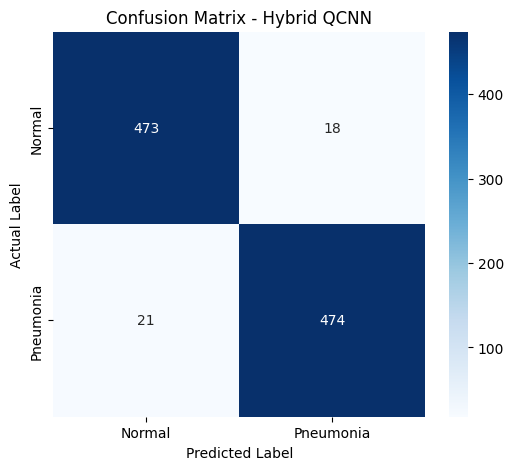


Classification Report:

              precision    recall  f1-score   support

      Normal       0.96      0.96      0.96       491
   Pneumonia       0.96      0.96      0.96       495

    accuracy                           0.96       986
   macro avg       0.96      0.96      0.96       986
weighted avg       0.96      0.96      0.96       986



In [34]:
############################################
# 🔹 Confusion Matrix
############################################

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in testloader:

        outputs = model(images)

        probs = torch.sigmoid(outputs)

        preds = (probs > 0.5).float()

        all_preds.extend(
            preds.cpu().numpy().flatten()
        )

        all_labels.extend(
            labels.cpu().numpy().flatten()
        )

cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal','Pneumonia'],
    yticklabels=['Normal','Pneumonia']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Hybrid QCNN")

plt.show()

print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=[
            "Normal",
            "Pneumonia"
        ]
    )
)

In [35]:
############################################
# 🔹 Qubit Importance Analysis
############################################

baseline_acc = accuracy

importance_q1 = []
importance_q2 = []

def evaluate_with_qubit_removed(model, testloader,
                                branch, qubit_idx):

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in testloader:

            labels = labels.unsqueeze(1)

            # CNN feature extraction
            x = model.conv(images)
            x = model.flatten(x)
            x = model.fc1(x)
            x = torch.tanh(x) * np.pi

            # Quantum outputs
            x1 = model.quantum1(x)
            x2 = model.quantum2(x)

            # Remove selected qubit
            if branch == 1:
                x1[:, qubit_idx] = 0

            elif branch == 2:
                x2[:, qubit_idx] = 0

            # Combine
            q_out = torch.cat([x1, x2], dim=1)

            outputs = model.fc2(q_out)

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Layer 1 importance
for q in range(n_qubits):

    acc = evaluate_with_qubit_removed(
        model,
        testloader,
        branch=1,
        qubit_idx=q
    )

    imp = baseline_acc - acc

    importance_q1.append(imp)

    print(
        f"Layer1 Qubit {q}: "
        f"Accuracy={acc:.2f}% "
        f"Importance={imp:.2f}"
    )


# Layer 2 importance
for q in range(n_qubits):

    acc = evaluate_with_qubit_removed(
        model,
        testloader,
        branch=2,
        qubit_idx=q
    )

    imp = baseline_acc - acc

    importance_q2.append(imp)

    print(
        f"Layer2 Qubit {q}: "
        f"Accuracy={acc:.2f}% "
        f"Importance={imp:.2f}"
    )

Layer1 Qubit 0: Accuracy=96.04% Importance=0.41
Layer1 Qubit 1: Accuracy=96.04% Importance=0.41
Layer1 Qubit 2: Accuracy=96.25% Importance=0.20
Layer1 Qubit 3: Accuracy=96.04% Importance=0.41
Layer1 Qubit 4: Accuracy=96.04% Importance=0.41
Layer1 Qubit 5: Accuracy=95.94% Importance=0.51
Layer2 Qubit 0: Accuracy=96.04% Importance=0.41
Layer2 Qubit 1: Accuracy=96.04% Importance=0.41
Layer2 Qubit 2: Accuracy=96.04% Importance=0.41
Layer2 Qubit 3: Accuracy=96.04% Importance=0.41
Layer2 Qubit 4: Accuracy=96.04% Importance=0.41
Layer2 Qubit 5: Accuracy=96.04% Importance=0.41


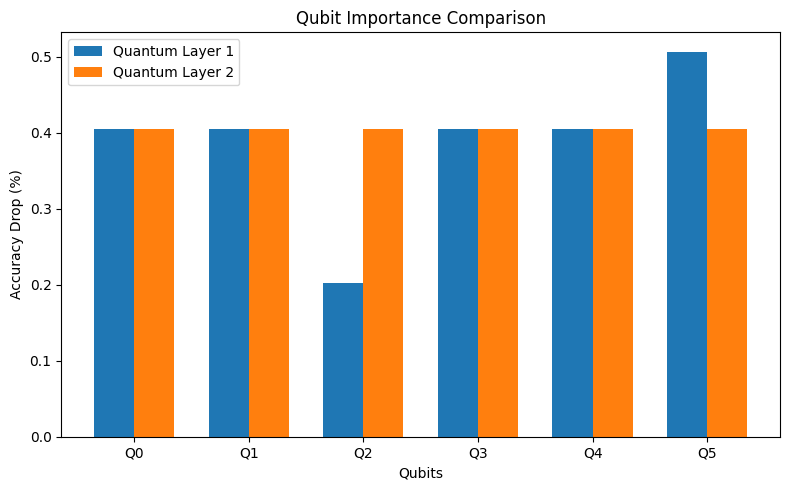

In [36]:
############################################
# 🔹 Plot Qubit Importance
############################################

import matplotlib.pyplot as plt
import numpy as np

qubits = np.arange(n_qubits)

plt.figure(figsize=(8,5))

width = 0.35

plt.bar(
    qubits - width/2,
    importance_q1,
    width,
    label="Quantum Layer 1"
)

plt.bar(
    qubits + width/2,
    importance_q2,
    width,
    label="Quantum Layer 2"
)

plt.xticks(qubits,
           [f"Q{i}" for i in range(n_qubits)])

plt.xlabel("Qubits")
plt.ylabel("Accuracy Drop (%)")
plt.title("Qubit Importance Comparison")

plt.legend()

plt.tight_layout()
plt.show()

## More improvement in 2 diff quantum layers

## FINAL QCNN WITH MORE IMPROVEMENT (ACCURACY 96.45%)

In [28]:
# Install PennyLane Accuracy 95.54
!pip install pennylane pennylane-lightning -q

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import tensorflow as tf

############################################
# 🔹 GLOBAL SEEDS
############################################
seed = 42
os.environ["PYTHONHASHSEED"] = str(seed)
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
tf.random.set_seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

############################################
# 🔹 Convert TensorFlow Dataset → NumPy
############################################
def tf_to_numpy(dataset):
    images, labels = [], []
    for x, y in dataset:
        images.append(x.numpy())
        labels.append(y.numpy())
    return np.concatenate(images), np.concatenate(labels)

X_train, y_train = tf_to_numpy(train_ds)
X_test, y_test   = tf_to_numpy(test_ds)

############################################
# 🔹 Convert NumPy → PyTorch
############################################
X_train = torch.tensor(X_train).permute(0,3,1,2).float() / 255.0
X_test  = torch.tensor(X_test).permute(0,3,1,2).float() / 255.0

y_train = torch.tensor(y_train).float()
y_test  = torch.tensor(y_test).float()

# Binary labels (unchanged)
y_train = (y_train > 0).float()
y_test  = (y_test > 0).float()

############################################
# 🔹 DataLoader
############################################
train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test, y_test)

g = torch.Generator()
g.manual_seed(seed)

trainloader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=g)
testloader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

n_qubits = 6
dev = qml.device("default.qubit", wires=n_qubits)

# 🔹 Quantum Circuit 1
@qml.qnode(dev, interface="torch")
def quantum_circuit_1_improved(inputs, weights):
    
    # 🔹 Data embedding (re-uploading for better expressivity)
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    
    for l in range(weights.shape[0]):
        
        # Trainable rotations
        for i in range(n_qubits):
            qml.RX(weights[l][i][0], wires=i)
            qml.RY(weights[l][i][1], wires=i)
            qml.RZ(weights[l][i][2], wires=i)
        
        # Entanglement block 1: Linear chain (local)
        for i in range(n_qubits - 1):
            qml.CNOT(wires=[i, i+1])
        
        # Entanglement block 2: Reverse chain
        for i in range(n_qubits - 1, 0, -1):
            qml.CNOT(wires=[i, i-1])
        
        # Entanglement block 3: Long-range (skip connections)
        for i in range(n_qubits):
            qml.CZ(wires=[i, (i+2) % n_qubits])
        
        # Entanglement block 4: Parametric entanglement
        for i in range(n_qubits - 1):
            qml.CRX(weights[l][i][0], wires=[i, i+1])
        
        # Data re-uploading (VERY IMPORTANT for QCNN)
        qml.AngleEmbedding(inputs, wires=range(n_qubits))
    
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]


# 🔹 Quantum Circuit 2 (different ansatz)
@qml.qnode(dev, interface="torch")
def quantum_circuit_2(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    
    # Different structure: add extra rotations + different entanglement
    for i in range(n_qubits):
        qml.RY(weights[0][i][0], wires=i)
        qml.RZ(weights[0][i][1], wires=i)
    
    for i in range(n_qubits - 1):
        qml.CNOT(wires=[i, i+1])
    
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]


weight_shapes = {"weights": (5, n_qubits, 3)}

quantum_layer1 = qml.qnn.TorchLayer(quantum_circuit_1_improved, weight_shapes)
quantum_layer2 = qml.qnn.TorchLayer(quantum_circuit_2, weight_shapes)

############################################
# 🔹 Hybrid Multi-Branch QCNN
############################################
class HybridQCNN(nn.Module):
    def __init__(self):
        super(HybridQCNN, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3,16,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((6,6)),
            nn.BatchNorm2d(64)
        )

        self.flatten = nn.Flatten()

        self.fc1 = nn.Sequential(
            nn.Linear(64*6*6,128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n_qubits)
        )

        self.quantum1 = quantum_layer1
        self.quantum2 = quantum_layer2

        self.fc2 = nn.Linear(2 * n_qubits, 1)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.fc1(x)

        x = torch.tanh(x) * np.pi

        x1 = self.quantum1(x)
        x2 = self.quantum2(x)

        x = torch.cat([x1, x2], dim=1)

        x = self.fc2(x)
        return x

############################################
# 🔹 Model
############################################
model = HybridQCNN()

############################################
# 🔹 Training Setup
############################################
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()])
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.0003)

############################################
# 🔹 Training Loop
############################################
for epoch in range(20):
    running_loss = 0.0

    for images, labels in trainloader:
        labels = labels.unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {running_loss/len(trainloader):.4f}")

############################################
# 🔹 Testing
############################################
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        labels = labels.unsqueeze(1)

        outputs = model(images)
        probs = torch.sigmoid(outputs)
        predicted = (probs > 0.5).float()

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Epoch 1, Loss: 0.6926
Epoch 2, Loss: 0.6343
Epoch 3, Loss: 0.4635
Epoch 4, Loss: 0.3566
Epoch 5, Loss: 0.2835
Epoch 6, Loss: 0.2409
Epoch 7, Loss: 0.2129
Epoch 8, Loss: 0.1892
Epoch 9, Loss: 0.1702
Epoch 10, Loss: 0.1604
Epoch 11, Loss: 0.1460
Epoch 12, Loss: 0.1422
Epoch 13, Loss: 0.1345
Epoch 14, Loss: 0.1240
Epoch 15, Loss: 0.1226
Epoch 16, Loss: 0.1167
Epoch 17, Loss: 0.1100
Epoch 18, Loss: 0.1014
Epoch 19, Loss: 0.1092
Epoch 20, Loss: 0.1004
Test Accuracy: 96.45%


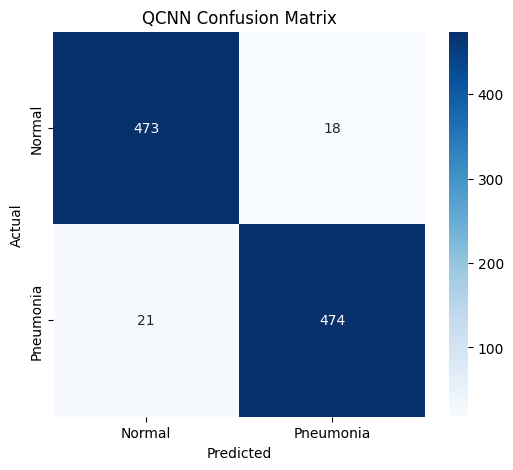

              precision    recall  f1-score   support

      Normal       0.96      0.96      0.96       491
   Pneumonia       0.96      0.96      0.96       495

    accuracy                           0.96       986
   macro avg       0.96      0.96      0.96       986
weighted avg       0.96      0.96      0.96       986



In [30]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in testloader:

        outputs = model(images)

        probs = torch.sigmoid(outputs)

        preds = (probs > 0.5).float()

        all_preds.extend(preds.cpu().numpy().flatten())
        all_labels.extend(labels.cpu().numpy().flatten())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal','Pneumonia'],
    yticklabels=['Normal','Pneumonia']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("QCNN Confusion Matrix")

plt.show()

print(classification_report(
    all_labels,
    all_preds,
    target_names=['Normal','Pneumonia']
))

In [31]:
############################################
# 🔹 Qubit Importance Analysis
############################################

baseline_acc = accuracy

importance_q1 = []
importance_q2 = []

def evaluate_with_qubit_removed(
        model,
        testloader,
        branch,
        qubit_idx):

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in testloader:

            labels = labels.unsqueeze(1)

            x = model.conv(images)
            x = model.flatten(x)
            x = model.fc1(x)

            x = torch.tanh(x) * np.pi

            q1 = model.quantum1(x)
            q2 = model.quantum2(x)

            if branch == 1:
                q1[:, qubit_idx] = 0

            elif branch == 2:
                q2[:, qubit_idx] = 0

            q_out = torch.cat([q1, q2], dim=1)

            outputs = model.fc2(q_out)

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


# Branch 1
for q in range(n_qubits):

    acc = evaluate_with_qubit_removed(
        model,
        testloader,
        branch=1,
        qubit_idx=q
    )

    imp = baseline_acc - acc

    importance_q1.append(imp)

    print(
        f"Improved Layer1 Q{q}: "
        f"Accuracy={acc:.2f}% "
        f"Importance={imp:.2f}"
    )


# Branch 2
for q in range(n_qubits):

    acc = evaluate_with_qubit_removed(
        model,
        testloader,
        branch=2,
        qubit_idx=q
    )

    imp = baseline_acc - acc

    importance_q2.append(imp)

    print(
        f"Layer2 Q{q}: "
        f"Accuracy={acc:.2f}% "
        f"Importance={imp:.2f}"
    )

Improved Layer1 Q0: Accuracy=96.04% Importance=0.41
Improved Layer1 Q1: Accuracy=96.04% Importance=0.41
Improved Layer1 Q2: Accuracy=96.25% Importance=0.20
Improved Layer1 Q3: Accuracy=96.04% Importance=0.41
Improved Layer1 Q4: Accuracy=96.04% Importance=0.41
Improved Layer1 Q5: Accuracy=95.94% Importance=0.51
Layer2 Q0: Accuracy=96.04% Importance=0.41
Layer2 Q1: Accuracy=96.04% Importance=0.41
Layer2 Q2: Accuracy=96.04% Importance=0.41
Layer2 Q3: Accuracy=96.04% Importance=0.41
Layer2 Q4: Accuracy=96.04% Importance=0.41
Layer2 Q5: Accuracy=96.04% Importance=0.41


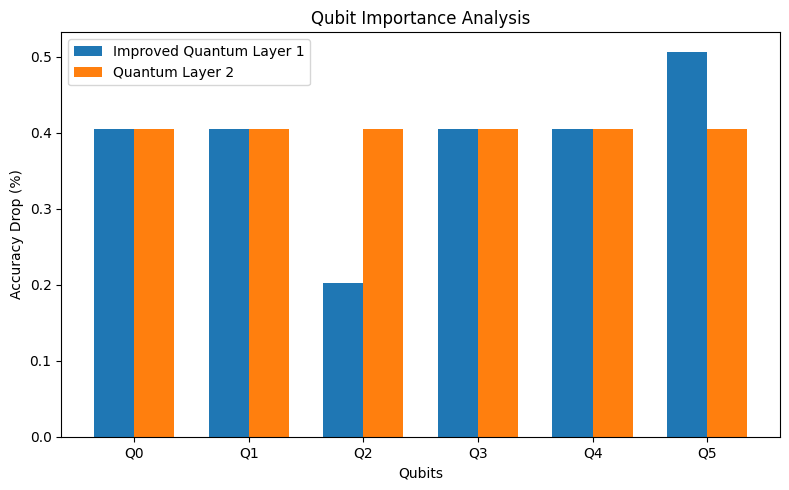

In [33]:
############################################
# 🔹 Plot Qubit Importance
############################################

import matplotlib.pyplot as plt
import numpy as np

qubits = np.arange(n_qubits)

plt.figure(figsize=(8,5))

width = 0.35

plt.bar(
    qubits - width/2,
    importance_q1,
    width,
    label="Improved Quantum Layer 1"
)

plt.bar(
    qubits + width/2,
    importance_q2,
    width,
    label="Quantum Layer 2"
)

plt.xticks(
    qubits,
    [f"Q{i}" for i in range(n_qubits)]
)

plt.xlabel("Qubits")
plt.ylabel("Accuracy Drop (%)")
plt.title("Qubit Importance Analysis")

plt.legend()

plt.tight_layout()
plt.show()